# Preparación de imágenes: estandarización y troceado

Las imágenes del dataset vienen sin etiquetas, en carpetas por estudiante, con formatos, tamaños (de 1.4 a 24 megapíxeles) y orientaciones muy distintos. Antes de aplicar cualquier técnica de aprendizaje es necesario **estandarizarlas**.

Este notebook hace únicamente la preparación de los datos:

1. Montar Google Drive y localizar las imágenes.
2. Hacer un inventario (formato, dimensiones, orientación).
3. Estandarizar cada imagen: corregir la orientación y convertir a RGB. **La imagen original no se redimensiona.**
4. Trocear la imagen original, a su resolución completa, en *tiles* (imágenes pequeñas) y **solo entonces** reducir cada tile a 128 x 128 píxeles.
5. Guardar los tiles en Drive, una carpeta por estudiante.
6. Verificar el resultado.

## 1. Conectar con Google Drive

In [3]:
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    EN_COLAB = True
except ImportError:
    EN_COLAB = False
    print("No estás en Colab: se usarán las rutas locales de abajo.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
from pathlib import Path
RAIZ = Path("/content/drive/MyDrive/IA/imagenes")
print("¿Existe RAIZ?", RAIZ.exists())
if RAIZ.exists():
    print("Subcarpetas (estudiantes):")
    for p in sorted(RAIZ.iterdir()):
        if p.is_dir():
            n = len([f for f in p.rglob("*") if f.suffix.lower() in {".jpg",".jpeg",".png",".webp",".bmp",".tif",".tiff"}])
            print(f"  {p.name}: {n} imágenes")

¿Existe RAIZ? True
Subcarpetas (estudiantes):
  Franky_Quispe_Zarate: 75 imágenes
  alvaro_david_arancibia_estrada: 10 imágenes
  camila_fernanda_montecinos_solis: 0 imágenes
  carlos_walter_pacheco_lora: 84 imágenes
  erick_alexander_ochoa_paz: 30 imágenes
  jose_manuel_gallardo_laura: 14 imágenes
  laura_luciana_diaz_campos: 27 imágenes
  luis_fernando_quispe_sullca: 10 imágenes
  maria_luciana_salinas_vilar: 181 imágenes
  pedro_jhoel_antonio_magne_ordoñez: 8 imágenes


## 2. Configuración


Los tiles se cortan de la imagen **original**, así que hay que decidir de qué tamaño (en píxeles de la original) es cada recorte. Hay dos modos:

- `MODO = "fijo"`: todos los tiles miden `TILE_ORIG` x `TILE_ORIG` píxeles de la imagen original. Conserva el máximo detalle, pero las fotos de 24 MP generan muchos más tiles (y cada uno cubre una zona más pequeña de la escena) que las de 1.4 MP.
- `MODO = "proporcional"`: el tile mide `lado corto / FILAS`, de modo que cada foto se divide en la misma cantidad de filas sin importar su resolución. Cada tile cubre la misma fracción de la escena en todas las fotos.

Después de recortar, **cada tile se redimensiona a `TILE` x `TILE`** (el enunciado pide entre 64 x 64 y 128 x 128).

`MAX_TILES_POR_FOTO` (opcional) limita los tiles por foto, eligiéndolos al azar con semilla fija, para que las fotos de alta resolución no dominen el dataset.

In [ ]:
if EN_COLAB:
    RAIZ        = Path("/content/drive/MyDrive/IA/imagenes")      
    SALIDA_BASE = Path("/content/drive/MyDrive/IA/tiles_128")     
else:
    RAIZ        = Path("imagenes")
    SALIDA_BASE = Path("tiles_128")

TILE = 128                    
MODO = "proporcional"         
TILE_ORIG = 512               
FILAS = 6                     
MAX_TILES_POR_FOTO = 40     
SEMILLA = 42
EXTENSIONES = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}


nombre_config = f"{MODO}_filas{FILAS}" if MODO == "proporcional" else f"fijo_{TILE_ORIG}px"
if MAX_TILES_POR_FOTO is not None:
    nombre_config += f"_max{MAX_TILES_POR_FOTO}"
SALIDA = SALIDA_BASE / nombre_config
print("Los tiles se guardarán en:", SALIDA)

assert MODO in ("fijo", "proporcional")
assert RAIZ.exists(), f"No existe la carpeta {RAIZ}. Revisa la ruta."

Los tiles se guardarán en: /content/drive/MyDrive/IA/tiles_128/proporcional_filas6_max40


## 3. Inventario de las imágenes

Antes de procesar, revisamos qué tenemos: formato, dimensiones y orientación. Muchos celulares guardan la foto "acostada" y añaden una etiqueta (*EXIF*) que indica cómo debe girarse para verla derecha. La función `ImageOps.exif_transpose` aplica esa etiqueta: **no rota ni voltea la foto a nuestro gusto**, solo la muestra tal como se vio al tomarla.

In [ ]:
from PIL import Image, ImageOps
import numpy as np
import pandas as pd

def listar_imagenes(raiz):
    rutas = [r for r in sorted(raiz.rglob("*")) if r.suffix.lower() in EXTENSIONES]
    return rutas

def plan_de_rejilla(w, h):
    
    lado = TILE_ORIG if MODO == "fijo" else max(TILE, min(w, h) // FILAS)
    lado = min(lado, w, h)                     
    nx, ny = w // lado, h // lado
    ox, oy = (w - nx * lado) // 2, (h - ny * lado) // 2   
    return lado, nx, ny, ox, oy

def posiciones_de_foto(w, h):
    
    lado, nx, ny, ox, oy = plan_de_rejilla(w, h)
    posiciones = [(i, j) for j in range(ny) for i in range(nx)]
    if MAX_TILES_POR_FOTO is not None and len(posiciones) > MAX_TILES_POR_FOTO:
        rng = np.random.default_rng(SEMILLA)                          # misma selección en cada ejecución
        elegidas = np.sort(rng.choice(len(posiciones), MAX_TILES_POR_FOTO, replace=False))
        posiciones = [posiciones[k] for k in elegidas]
    return lado, nx, ny, ox, oy, posiciones

def tamano_real(ruta):
    
    with Image.open(ruta) as im:
        w, h = im.size
        if im.getexif().get(274) in (5, 6, 7, 8):    
            w, h = h, w
    return w, h

rutas = listar_imagenes(RAIZ)

filas = []
for ruta in rutas:
    try:
        with Image.open(ruta) as im:
            w_raw, h_raw = im.size
            exif = im.getexif().get(274)           
            w, h = ImageOps.exif_transpose(im).size 
            lado, nx, ny, _, _ = plan_de_rejilla(w, h)
            n_tiles = nx * ny if MAX_TILES_POR_FOTO is None else min(nx * ny, MAX_TILES_POR_FOTO)
            filas.append({
                "estudiante": ruta.relative_to(RAIZ).parts[0],
                "archivo": ruta.name,
                "formato": im.format,
                "ancho": w, "alto": h,
                "orientacion": "vertical" if h > w else "horizontal",
                "exif_orientacion": exif,
                "megapixeles": round(w * h / 1e6, 1),
                "tile_px_original": lado,
                "rejilla": f"{nx}x{ny}",
                "tiles": n_tiles,
            })
    except Exception as e:
        filas.append({"estudiante": ruta.relative_to(RAIZ).parts[0], "archivo": ruta.name, "formato": f"ERROR: {e}"})

inventario = pd.DataFrame(filas)
print(f"Imágenes encontradas: {len(inventario)} en {inventario['estudiante'].nunique()} carpetas")
inventario.head(20)

Imágenes encontradas: 447 en 10 carpetas


,estudiante,archivo,formato,ancho,alto,orientacion,exif_orientacion,megapixeles,tile_px_original,rejilla,tiles
0,Franky_Quispe_Zarate,271c1353-391f-4516-a609-01885f6ad6c1.jpg,JPEG,1599,899,horizontal,NaN,1.4,149,10x6,40
1,Franky_Quispe_Zarate,31a90e6d-b668-40d7-9b30-fabada0870d2.jpg,JPEG,1599,899,horizontal,NaN,1.4,149,10x6,40
2,Franky_Quispe_Zarate,3dc58585-fba1-416e-88e6-cefc9580cb95.jpg,JPEG,1599,899,horizontal,NaN,1.4,149,10x6,40
3,Franky_Quispe_Zarate,IMG_9045.JPG,MPO,5712,4284,horizontal,1.0,24.5,714,8x6,40
4,Franky_Quispe_Zarate,IMG_9046.JPG,MPO,5712,4284,horizontal,1.0,24.5,714,8x6,40
5,Franky_Quispe_Zarate,IMG_9047.JPG,MPO,5712,4284,horizontal,1.0,24.5,714,8x6,40
6,Franky_Quispe_Zarate,IMG_9048.JPG,MPO,5712,4284,horizontal,1.0,24.5,714,8x6,40
7,Franky_Quispe_Zarate,IMG_9050.JPG,MPO,5712,4284,horizontal,1.0,24.5,714,8x6,40
8,Franky_Quispe_Zarate,IMG_9051.JPG,MPO,5712,4284,horizontal,1.0,24.5,714,8x6,40
9,Franky_Quispe_Zarate,IMG_9052.JPG,MPO,5712,4284,horizontal,1.0,24.5,714,8x6,40


In [19]:
print("Imágenes por estudiante:")
print(inventario.groupby("estudiante").size().to_string())
print()
print("Orientación:")
print(inventario["orientacion"].value_counts().to_string())
print()
print("Megapíxeles (min / mediana / max):",
      inventario["megapixeles"].min(), "/", inventario["megapixeles"].median(), "/", inventario["megapixeles"].max())
print("Formatos:", inventario["formato"].value_counts().to_dict())
print()
print(f"Modo '{MODO}' -> tiles esperados en total: {inventario['tiles'].sum()}")
print("Tiles esperados por estudiante (revisa que no haya un autor que domine):")
print(inventario.groupby("estudiante")["tiles"].sum().to_string())

Imágenes por estudiante:
estudiante
Franky_Quispe_Zarate                   75
alvaro_david_arancibia_estrada         10
camila_fernanda_montecinos_solis        8
carlos_walter_pacheco_lora             84
erick_alexander_ochoa_paz              30
jose_manuel_gallardo_laura             14
laura_luciana_diaz_campos              27
luis_fernando_quispe_sullca            10
maria_luciana_salinas_vilar           181
pedro_jhoel_antonio_magne_ordoñez      8

Orientación:
orientacion
vertical      264
horizontal    183

Megapíxeles (min / mediana / max): 0.7 / 12.2 / 24.5
Formatos: {'JPEG': 375, 'MPO': 72}

Modo 'proporcional' -> tiles esperados en total: 17880
Tiles esperados por estudiante (revisa que no haya un autor que domine):
estudiante
Franky_Quispe_Zarate                  3000
alvaro_david_arancibia_estrada         400
camila_fernanda_montecinos_solis       320
carlos_walter_pacheco_lora            3360
erick_alexander_ochoa_paz             1200
jose_manuel_gallardo_laura            

## 4. Estandarización y troceado de una imagen

Para cada imagen:

1. `Image.open` la abre **a resolución completa** (no se reduce).
2. `exif_transpose` corrige la orientación según el celular. No rota ni voltea la foto a nuestro gusto: solo la muestra como se vio al tomarla.
3. `convert("RGB")` unifica el formato de color.
4. Con `plan_de_rejilla` se calcula el tamaño del recorte y la rejilla, centrada en la imagen (el sobrante que no completa un tile se reparte entre los bordes).
5. Cada recorte se saca de la imagen original y **recién entonces** se redimensiona a `TILE` x `TILE` con `resize(..., LANCZOS)`.

In [20]:
import numpy as np

def tiles_de_foto(ruta):
    """Devuelve (tiles, info). tiles: lista de imágenes RGB de TILE x TILE;
    info: dict con lado del recorte original, rejilla y posición (columna, fila) de cada tile."""
    im = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")    # resolución original
    w, h = im.size
    lado, nx, ny, ox, oy, posiciones = posiciones_de_foto(w, h)
    tiles = []
    for (i, j) in posiciones:
        caja = (ox + i * lado, oy + j * lado, ox + (i + 1) * lado, oy + (j + 1) * lado)
        tiles.append(im.crop(caja).resize((TILE, TILE), Image.LANCZOS))   # se reduce SOLO el tile
    info = {"lado_original": lado, "nx": nx, "ny": ny, "ox": ox, "oy": oy,
            "ancho": w, "alto": h, "posiciones": posiciones}
    return tiles, info

# Prueba con la primera imagen
tiles, info = tiles_de_foto(rutas[0])
print(f"{rutas[0].name}: imagen {info['ancho']}x{info['alto']} -> recortes de {info['lado_original']}x{info['lado_original']} px "
      f"(rejilla {info['nx']}x{info['ny']}) -> {len(tiles)} tiles reducidos a {tiles[0].size}")

271c1353-391f-4516-a609-01885f6ad6c1.jpg: imagen 1599x899 -> recortes de 149x149 px (rejilla 10x6) -> 40 tiles reducidos a (128, 128)


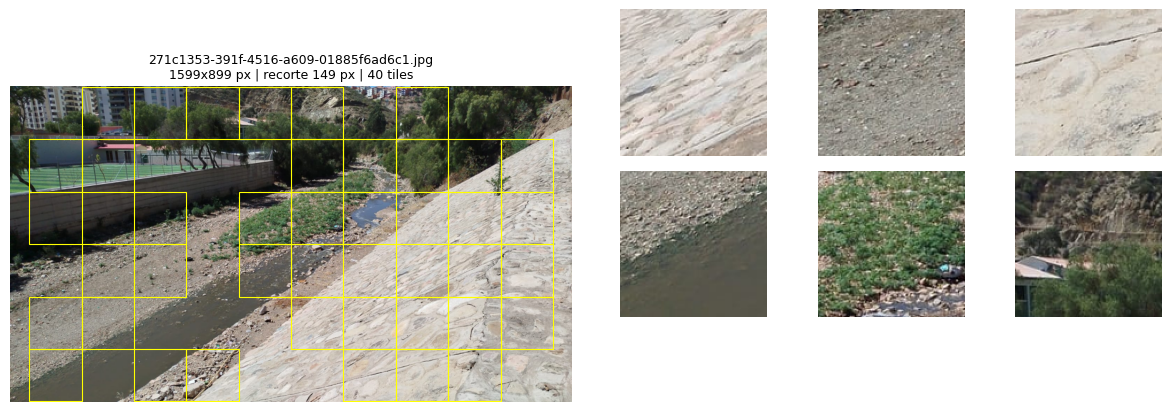

In [21]:
import matplotlib.pyplot as plt

def mostrar_rejilla(ruta, n_ejemplos=6):
    """Muestra la foto con la rejilla de recortes y algunos tiles ya reducidos."""
    tiles, info = tiles_de_foto(ruta)
    vista = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")
    esc = 900 / max(vista.size)
    vista = vista.resize((round(vista.width * esc), round(vista.height * esc)))
    lado = info["lado_original"]

    fig = plt.figure(figsize=(12, 5))
    ax = fig.add_subplot(1, 2, 1)
    ax.imshow(vista)
    for (i, j) in info["posiciones"]:
        x0, y0 = (info["ox"] + i * lado) * esc, (info["oy"] + j * lado) * esc
        ax.add_patch(plt.Rectangle((x0, y0), lado * esc, lado * esc, fill=False, ec="yellow", lw=0.8))
    ax.set_title(f"{ruta.name}\n{info['ancho']}x{info['alto']} px | recorte {lado} px | {len(tiles)} tiles", fontsize=9)
    ax.axis("off")

    rng = np.random.default_rng(SEMILLA)
    sel = rng.choice(len(tiles), min(n_ejemplos, len(tiles)), replace=False)
    for p, k in enumerate(sel):
        a = fig.add_subplot(3, 6, 4 + (p % 3) + 6 * (p // 3))
        a.imshow(tiles[k]); a.axis("off")
    plt.tight_layout(); plt.show()

mostrar_rejilla(rutas[0])

Para ver qué se gana al cortar la original: abajo, un mismo recorte antes y después de reducirlo. El recorte de la izquierda tiene todo el detalle de la foto original; el de la derecha es lo que verá el modelo.

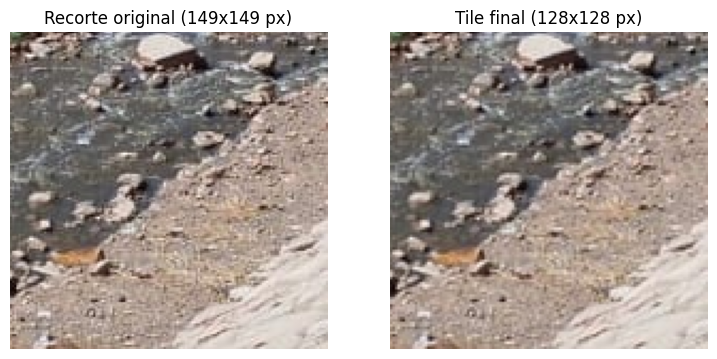

In [22]:
im0 = ImageOps.exif_transpose(Image.open(rutas[0])).convert("RGB")
lado, nx, ny, ox, oy = plan_de_rejilla(*im0.size)
i, j = nx // 2, ny // 2                                    # un tile del centro
recorte = im0.crop((ox + i*lado, oy + j*lado, ox + (i+1)*lado, oy + (j+1)*lado))

plt.figure(figsize=(9, 4.5))
plt.subplot(121); plt.imshow(recorte); plt.axis("off"); plt.title(f"Recorte original ({lado}x{lado} px)")
plt.subplot(122); plt.imshow(recorte.resize((TILE, TILE), Image.LANCZOS)); plt.axis("off"); plt.title(f"Tile final ({TILE}x{TILE} px)")
plt.show()

## 5. Procesar todas las carpetas y registrar de dónde sale cada tile

Se recorre cada imagen y se guardan sus tiles en `SALIDA/<estudiante>/`. Los nombres son `img001_000.png`: el primer número es el de la imagen dentro de la carpeta y el segundo el del tile. Se guardan en **PNG** (sin pérdida).

Al mismo tiempo se construye una **tabla de metadatos** (`tiles_metadata.csv`) con una fila por tile que registra: el archivo del tile, el **estudiante (autor)**, la **foto original** de la que salió, la posición (columna, fila) dentro de esa foto y el tamaño del recorte original. Esta tabla es lo que permite más adelante:

- separar entrenamiento y prueba **por autor** (evitar que fotos del mismo estudiante estén en ambos conjuntos),
- saber de qué foto vino cada tile,
- no depender de adivinar el autor a partir del nombre de la carpeta.

Si una imagen falla, se anota en `errores` y el proceso continúa. Si todos los tiles de una imagen ya existen, se omiten (puedes volver a ejecutar la celda si Colab se desconecta); la tabla se reconstruye completa en cada ejecución.

In [ ]:
import time

t0 = time.time()
nuevos, errores, contador, filas_meta = 0, [], {}, []

for ruta in rutas:
    autor = ruta.relative_to(RAIZ).parts[0]
    contador[autor] = contador.get(autor, 0) + 1
    foto_id = f"img{contador[autor]:03d}"
    destino = SALIDA / autor
    destino.mkdir(parents=True, exist_ok=True)
    try:
        w, h = tamano_real(ruta)
        lado, nx, ny, ox, oy, posiciones = posiciones_de_foto(w, h)

        
        for k, (i, j) in enumerate(posiciones):
            filas_meta.append({
                "tile_archivo": f"{autor}/{foto_id}_{k:03d}.png",
                "autor": autor,
                "foto_original": ruta.relative_to(RAIZ).as_posix(),
                "foto_id": foto_id,
                "tile_k": k, "columna": i, "fila": j,
                "lado_original_px": lado, "ancho_foto": w, "alto_foto": h,
            })

        
        if all((destino / f"{foto_id}_{k:03d}.png").exists() for k in range(len(posiciones))):
            continue
        tiles, info = tiles_de_foto(ruta)
        for k, t in enumerate(tiles):
            t.save(destino / f"{foto_id}_{k:03d}.png")
        nuevos += len(tiles)
    except Exception as e:
        errores.append((str(ruta), str(e)))
        filas_meta = [f for f in filas_meta if not (f["autor"] == autor and f["foto_id"] == foto_id)]

metadata = pd.DataFrame(filas_meta)
metadata.to_csv(SALIDA / "tiles_metadata.csv", index=False)

print(f"Tiles nuevos: {nuevos} | tiempo: {time.time() - t0:.1f} s | errores: {len(errores)}")
print(f"Tabla de metadatos: {len(metadata)} filas -> {SALIDA / 'tiles_metadata.csv'}")
for r, e in errores:
    print("  ERROR:", r, "->", e)
metadata.head()

Tiles nuevos: 320 | tiempo: 16.1 s | errores: 0
Tabla de metadatos: 17880 filas -> /content/drive/MyDrive/IA/tiles_128/proporcional_filas6_max40/tiles_metadata.csv


,tile_archivo,autor,foto_original,foto_id,tile_k,columna,fila,lado_original_px,ancho_foto,alto_foto
0,Franky_Quispe_Zarate/img001_000.png,Franky_Quispe_Zarate,Franky_Quispe_Zarate/271c1353-391f-4516-a609-0...,img001,0,1,0,149,1599,899
1,Franky_Quispe_Zarate/img001_001.png,Franky_Quispe_Zarate,Franky_Quispe_Zarate/271c1353-391f-4516-a609-0...,img001,1,2,0,149,1599,899
2,Franky_Quispe_Zarate/img001_002.png,Franky_Quispe_Zarate,Franky_Quispe_Zarate/271c1353-391f-4516-a609-0...,img001,2,3,0,149,1599,899
3,Franky_Quispe_Zarate/img001_003.png,Franky_Quispe_Zarate,Franky_Quispe_Zarate/271c1353-391f-4516-a609-0...,img001,3,4,0,149,1599,899
4,Franky_Quispe_Zarate/img001_004.png,Franky_Quispe_Zarate,Franky_Quispe_Zarate/271c1353-391f-4516-a609-0...,img001,4,5,0,149,1599,899


## 6. Verificación

Comprobamos cuántos tiles hay por carpeta y que todos tienen el mismo tamaño y formato.

In [ ]:
archivos = sorted(SALIDA.rglob("*.png"))
print(f"Total de tiles guardados: {len(archivos)}\n")


en_tabla = set(metadata["tile_archivo"])
en_disco = {a.relative_to(SALIDA).as_posix() for a in archivos}
assert en_tabla == en_disco, f"Tabla y archivos no coinciden: {len(en_tabla - en_disco)} faltan en disco, {len(en_disco - en_tabla)} sobran"
print("Metadatos y archivos coinciden: OK\n")

print("Tiles por estudiante:")
por_autor = {}
for a in archivos:
    por_autor[a.parent.name] = por_autor.get(a.parent.name, 0) + 1
for autor, n in por_autor.items():
    print(f"  {autor:40s} {n:5d}")

tamanos, modos = set(), set()
for a in archivos[::max(1, len(archivos) // 200)]:      
    with Image.open(a) as im:
        tamanos.add(im.size); modos.add(im.mode)
print("\nTamaños encontrados:", tamanos, "| Modos:", modos)
assert tamanos == {(TILE, TILE)} and modos == {"RGB"}, "Hay tiles con tamaño o modo distinto"

Total de tiles guardados: 17880

Metadatos y archivos coinciden: OK

Tiles por estudiante:
  Franky_Quispe_Zarate                      3000
  alvaro_david_arancibia_estrada             400
  camila_fernanda_montecinos_solis           320
  carlos_walter_pacheco_lora                3360
  erick_alexander_ochoa_paz                 1200
  jose_manuel_gallardo_laura                 560
  laura_luciana_diaz_campos                 1080
  luis_fernando_quispe_sullca                400
  maria_luciana_salinas_vilar               7240
  pedro_jhoel_antonio_magne_ordoñez         320

Tamaños encontrados: {(128, 128)} | Modos: {'RGB'}


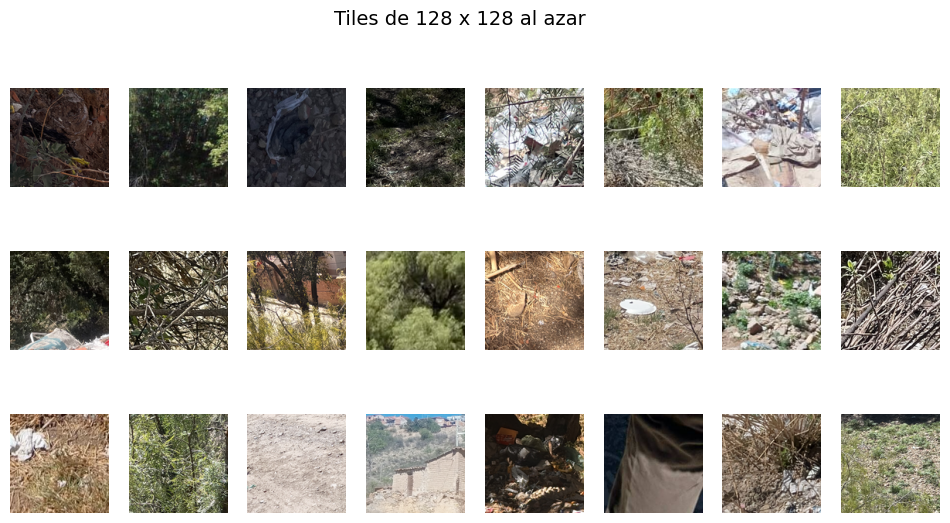

In [ ]:

rng = np.random.default_rng(42)
muestra = rng.choice(len(archivos), size=min(24, len(archivos)), replace=False)

plt.figure(figsize=(12, 6))
for p, idx in enumerate(muestra):
    plt.subplot(3, 8, p + 1)
    plt.imshow(Image.open(archivos[idx]))
    plt.axis("off")
plt.suptitle("Tiles de 128 x 128 al azar", fontsize=14)
plt.show()

## Resumen

Las imágenes quedaron estandarizadas: mismo formato (RGB, PNG), mismo tamaño (128 x 128), orientación corregida y organizadas por estudiante en `SALIDA`. Estos tiles son la entrada para los siguientes pasos del proyecto.